In [2]:
# Environment setup is performed separately using requirements.txt.
# python -m pip install -r requirements.txt


# Stage 1: Load and Check Data

## Environment

Install requirements.txt once in the chosen Python environment.
Normal notebook runs only import packages and read the saved snapshot.

- pandas: manipulate tables.
- NumPy: numerical calculations.
- Matplotlib: plotting.
- scikit-learn: modeling and evaluation.
- yfinance: retained original download procedure.


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn
import yfinance as yf

print("All imports completed successfully")
print("pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("scikit-learn:", sklearn.__version__)
print("yfinance:", yf.__version__)

All imports completed successfully
pandas: 3.1.0
NumPy: 2.5.4
scikit-learn: 1.9.1
yfinance: 1.7.0


## Load the Saved Snapshot

SPY is an exchange-traded fund (ETF). Read its saved daily data rather than downloading again.


**Original data download code — reference only**

```python
raw = yf.download(
    "SPY",
    start="2010-01-01",       # Start date, inclusive
    end="2026-01-01",         # End date, exclusive
    auto_adjust=False,       # Keep unadjusted OHLC and a separate adjusted close
    actions=True,            # Include dividends and stock splits
    multi_level_index=False, # Use single-level column names
    progress=False,          # Hide the download progress bar
)

# Stop if the download did not return a non-empty table
if raw is None or raw.empty:
    raise RuntimeError(
        "No data was retrieved. Check the download error messages."
    )
```


In [4]:
raw = pd.read_csv(
    "data/spy_raw.csv",
    index_col=0,
    parse_dates=True,
)

display(raw.head())

,Adj Close,Capital Gains,Close,Dividends,High,Low,Open,Stock Splits,Volume
Date,,,,,,,,,
2010-01-04,84.368988,0.0,113.330002,0.0,113.389999,111.510002,112.370003,0.0,118944600
2010-01-05,84.592293,0.0,113.629997,0.0,113.680000,112.849998,113.260002,0.0,111579900
2010-01-06,84.651863,0.0,113.709999,0.0,113.989998,113.430000,113.519997,0.0,116074400
2010-01-07,85.009201,0.0,114.190002,0.0,114.330002,113.180000,113.500000,0.0,131091100
2010-01-08,85.292084,0.0,114.570000,0.0,114.620003,113.660004,113.889999,0.0,126402800


## Inspect the Data Structure

Display the column labels, date range, and first observations.


In [5]:
print("Column names:")
print(raw.columns.tolist()) 

print("\nDate range:")
print(raw.index.min(), "to", raw.index.max())

print("\nFirst five rows:")
display(raw.head())

Column names:
['Adj Close', 'Capital Gains', 'Close', 'Dividends', 'High', 'Low', 'Open', 'Stock Splits', 'Volume']

Date range:
2010-01-04 00:00:00 to 2025-12-31 00:00:00

First five rows:


,Adj Close,Capital Gains,Close,Dividends,High,Low,Open,Stock Splits,Volume
Date,,,,,,,,,
2010-01-04,84.368988,0.0,113.330002,0.0,113.389999,111.510002,112.370003,0.0,118944600
2010-01-05,84.592293,0.0,113.629997,0.0,113.680000,112.849998,113.260002,0.0,111579900
2010-01-06,84.651863,0.0,113.709999,0.0,113.989998,113.430000,113.519997,0.0,116074400
2010-01-07,85.009201,0.0,114.190002,0.0,114.330002,113.180000,113.500000,0.0,131091100
2010-01-08,85.292084,0.0,114.570000,0.0,114.620003,113.660004,113.889999,0.0,126402800


## Basic Data Quality Checks

Check data types, missing cell values, duplicate dates, ordering, positive prices, and OHLC consistency.

These checks do not detect an entirely absent trading-day row. No exchange-calendar completeness check has been performed.


In [6]:
# Inspect data types and missing values
raw.info()

print("\nMissing values per column:")
display(raw.isna().sum())

print("\nNumber of duplicate dates:", raw.index.duplicated().sum())
print("Dates sorted in ascending order:", raw.index.is_monotonic_increasing)

# Check whether price observations are positive
price_columns = ["Open", "High", "Low", "Close", "Adj Close"]

print("\nNumber of non-positive prices per column:")
display(raw[price_columns].le(0).sum())

# Check daily price consistency using unadjusted prices
invalid_price_range = (
    (raw["High"] < raw["Low"])
    | (raw["Open"] > raw["High"])
    | (raw["Open"] < raw["Low"])
    | (raw["Close"] > raw["High"])
    | (raw["Close"] < raw["Low"])
)

print("\nNumber of inconsistent daily price ranges:",
      invalid_price_range.sum())

<class 'pandas.DataFrame'>
DatetimeIndex: 4024 entries, 2010-01-04 to 2025-12-31
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Adj Close      4024 non-null   float64
 1   Capital Gains  4024 non-null   float64
 2   Close          4024 non-null   float64
 3   Dividends      4024 non-null   float64
 4   High           4024 non-null   float64
 5   Low            4024 non-null   float64
 6   Open           4024 non-null   float64
 7   Stock Splits   4024 non-null   float64
 8   Volume         4024 non-null   int64  
dtypes: float64(8), int64(1)
memory usage: 314.4 KB

Missing values per column:


Adj Close        0
Capital Gains    0
Close            0
Dividends        0
High             0
Low              0
Open             0
Stock Splits     0
Volume           0
dtype: int64


Number of duplicate dates: 0
Dates sorted in ascending order: True

Number of non-positive prices per column:


Open         0
High         0
Low          0
Close        0
Adj Close    0
dtype: int64


Number of inconsistent daily price ranges: 0


In [7]:
from pathlib import Path

# Keep the saved snapshot unchanged during analysis.
df = raw[["Adj Close"]].copy()
df = df.rename(columns={"Adj Close": "adj_close"})

# Calculate returns between consecutive trading-day observations.
df["return_1d"] = df["adj_close"].pct_change(fill_method=None)
display(df.head(6))


,adj_close,return_1d
Date,,
2010-01-04,84.368988,NaN
2010-01-05,84.592293,0.002647
2010-01-06,84.651863,0.000704
2010-01-07,85.009201,0.004221
2010-01-08,85.292084,0.003328
2010-01-11,85.411201,0.001397


In [8]:
train = df.loc["2010":"2018"].copy()
validation = df.loc["2019":"2022"].copy()
test = df.loc["2023":"2025"].copy()

print("Training rows:", len(train))
print("Validation rows:", len(validation))
print("Test rows:", len(test))

Training rows: 2264
Validation rows: 1008
Test rows: 752


**Observations**

The training set contains 2,263 valid daily returns.
The mean daily return is approximately 0.0474%, while the
daily standard deviation is approximately 0.9395%.
Daily returns range from approximately -6.51% to 5.05%.

**What I learned**

A positive historical average does not establish that
next-day returns are predictable.

In [9]:
print("Training return summary:")
display(train["return_1d"].describe())

print("Missing training returns:", train["return_1d"].isna().sum())
print(train["return_1d"].head(6))

Training return summary:


count    2263.000000
mean        0.000474
std         0.009395
min        -0.065123
25%        -0.003362
50%         0.000603
75%         0.005107
max         0.050525
Name: return_1d, dtype: float64

Missing training returns: 1
Date
2010-01-04         NaN
2010-01-05    0.002647
2010-01-06    0.000704
2010-01-07    0.004221
2010-01-08    0.003328
2010-01-11    0.001397
Name: return_1d, dtype: float64


**Observations**

Large daily moves appear in clusters, while some periods
show persistently smaller moves.

**What I learned**

This pattern is called volatility clustering.
Persistence in volatility does not by itself establish
predictability in return direction.

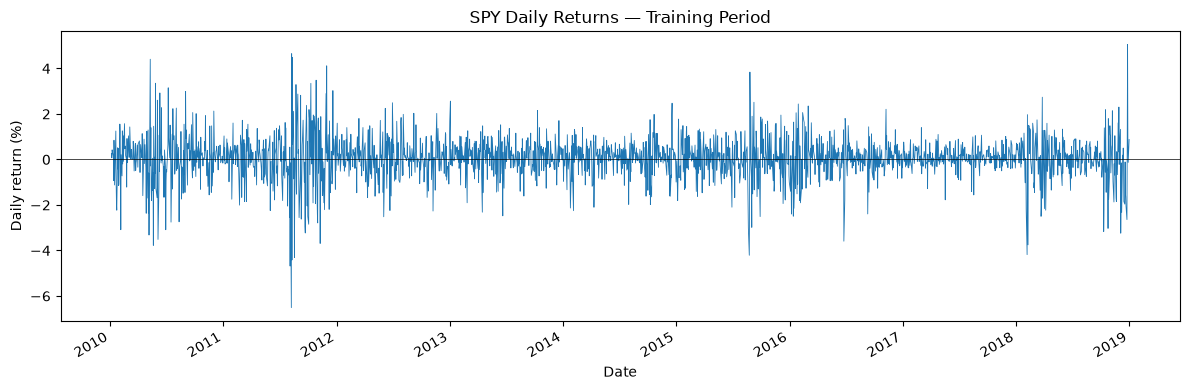

In [10]:
fig, ax = plt.subplots(figsize=(12, 4))

(train["return_1d"] * 100).plot(ax=ax, linewidth=0.6) 

ax.set_title("SPY Daily Returns — Training Period")
ax.set_xlabel("Date")
ax.set_ylabel("Daily return (%)")
ax.axhline(0, color="black", linewidth=0.5)

plt.tight_layout()
plt.show()


In [11]:
# Sample standard deviation of the current and previous 19 daily returns.
df["volatility_20d"] = df["return_1d"].rolling(window=20).std()
display(df[["return_1d", "volatility_20d"]].head(25))


,return_1d,volatility_20d
Date,,
2010-01-04,NaN,NaN
2010-01-05,0.002647,NaN
2010-01-06,0.000704,NaN
2010-01-07,0.004221,NaN
2010-01-08,0.003328,NaN
2010-01-11,0.001397,NaN
2010-01-12,-0.009326,NaN
2010-01-13,0.008447,NaN
2010-01-14,0.002704,NaN


In [12]:
# Move return values up one row; date labels remain unchanged.
df["target_next_1d"] = df["return_1d"].shift(-1)
display(df[["return_1d", "target_next_1d"]].head(6))


,return_1d,target_next_1d
Date,,
2010-01-04,NaN,0.002647
2010-01-05,0.002647,0.000704
2010-01-06,0.000704,0.004221
2010-01-07,0.004221,0.003328
2010-01-08,0.003328,0.001397
2010-01-11,0.001397,-0.009326


In [13]:
df["return_5d"] = df["adj_close"].pct_change(
    periods=5, #5 row before
    fill_method=None,
)

display(df[["adj_close", "return_1d", "return_5d"]].head(8))

,adj_close,return_1d,return_5d
Date,,,
2010-01-04,84.368988,NaN,NaN
2010-01-05,84.592293,0.002647,NaN
2010-01-06,84.651863,0.000704,NaN
2010-01-07,85.009201,0.004221,NaN
2010-01-08,85.292084,0.003328,NaN
2010-01-11,85.411201,0.001397,0.012353
2010-01-12,84.614647,-0.009326,0.000264
2010-01-13,85.329346,0.008447,0.008003


In [14]:
df["return_20d"] = df["adj_close"].pct_change(
    periods=20,
    fill_method=None,
)

display(df[["return_5d", "return_20d", "volatility_20d"]].head(23))

,return_5d,return_20d,volatility_20d
Date,,,
2010-01-04,NaN,NaN,NaN
2010-01-05,NaN,NaN,NaN
2010-01-06,NaN,NaN,NaN
2010-01-07,NaN,NaN,NaN
2010-01-08,NaN,NaN,NaN
2010-01-11,0.012353,NaN,NaN
2010-01-12,0.000264,NaN,NaN
2010-01-13,0.008003,NaN,NaN
2010-01-14,0.006480,NaN,NaN


In [15]:
df["return_lag1"] = df["return_1d"].shift(1)
df["return_lag2"] = df["return_1d"].shift(2)

display(
    df[["return_1d", "return_lag1", "return_lag2", "target_next_1d"]]
    .head(6)
)

,return_1d,return_lag1,return_lag2,target_next_1d
Date,,,,
2010-01-04,NaN,NaN,NaN,0.002647
2010-01-05,0.002647,NaN,NaN,0.000704
2010-01-06,0.000704,0.002647,NaN,0.004221
2010-01-07,0.004221,0.000704,0.002647,0.003328
2010-01-08,0.003328,0.004221,0.000704,0.001397
2010-01-11,0.001397,0.003328,0.004221,-0.009326


In [16]:
feature_columns = [
    "return_1d",
    "return_lag1",
    "return_lag2",
    "return_5d",
    "return_20d",
    "volatility_20d",
]

target_column = "target_next_1d"

model_data = df[feature_columns + [target_column]].dropna().copy()

print("Rows before filtering:", len(df))
print("Rows after filtering:", len(model_data))
print("Rows removed:", len(df) - len(model_data))
display( model_data)


Rows before filtering: 4024
Rows after filtering: 4003
Rows removed: 21


,return_1d,return_lag1,return_lag2,return_5d,return_20d,volatility_20d,target_next_1d
Date,,,,,,,
2010-02-02,0.012104,0.015551,-0.010869,0.009789,-0.026030,0.010585,-0.004983
2010-02-03,-0.004983,0.012104,0.015551,0.000000,-0.033442,0.010574,-0.030866
2010-02-04,-0.030866,-0.004983,0.012104,-0.019619,-0.063935,0.012403,0.002067
2010-02-05,0.002067,-0.030866,-0.004983,-0.006798,-0.065943,0.012344,-0.007219
2010-02-08,-0.007219,0.002067,-0.030866,-0.029067,-0.075762,0.012270,0.012561
...,...,...,...,...,...,...,...
2025-12-23,0.004570,0.006230,0.009064,0.016384,0.031796,0.005897,0.003518
2025-12-24,0.003518,0.004570,0.006230,0.031308,0.025777,0.005627,-0.000101
2025-12-26,-0.000101,0.003518,0.004570,0.023475,0.018641,0.005475,-0.003564


In [17]:
target_dates = pd.Series(df.index, index=df.index).shift(-1)
print(target_dates.head(6))
model_data["target_date"] = target_dates

display(
    model_data.loc["2018-12-27":"2019-01-04",
                   ["return_1d", "target_next_1d", "target_date"]]
)

Date
2010-01-04   2010-01-05
2010-01-05   2010-01-06
2010-01-06   2010-01-07
2010-01-07   2010-01-08
2010-01-08   2010-01-11
2010-01-11   2010-01-12
Name: Date, dtype: datetime64[us]


,return_1d,target_next_1d,target_date
Date,,,
2018-12-27,0.007677,-0.001290,2018-12-28
2018-12-28,-0.001290,0.008759,2018-12-31
2018-12-31,0.008759,0.001041,2019-01-02
2019-01-02,0.001041,-0.023863,2019-01-03
2019-01-03,-0.023863,0.033496,2019-01-04
2019-01-04,0.033496,0.007885,2019-01-07


In [18]:
train = model_data.loc["2010":"2018"].copy()
validation = model_data.loc["2019":"2022"].copy()
test = model_data.loc["2023":"2025"].copy()

train = train.loc[train["target_date"] < "2019-01-01"].copy()
validation = validation.loc[
    validation["target_date"] < "2023-01-01"
].copy()

print("Training rows:", len(train))
print("Validation rows:", len(validation))
print("Test rows:", len(test))

Training rows: 2243
Validation rows: 1007
Test rows: 751


# Models and Baselines

## Zero-Return and Historical-Mean Baselines


In [ ]:
train_mean = train[target_column].mean()

validation_predictions = pd.DataFrame(index=validation.index) #Create a data.frame to record
validation_predictions["actual"] = validation[target_column] #Insert column for actual data
validation_predictions["zero"] = 0.0
validation_predictions["historical_mean"] = train_mean

print("Training target mean:", train_mean)
display(validation_predictions.head())

Training target mean: 0.000489357721955866


,actual,zero,historical_mean
Date,,,
2019-01-02,-0.023863,0.0,0.000489
2019-01-03,0.033496,0.0,0.000489
2019-01-04,0.007885,0.0,0.000489
2019-01-07,0.009395,0.0,0.000489
2019-01-08,0.004673,0.0,0.000489


In [20]:
zero_mse = (
    validation_predictions["actual"]
    - validation_predictions["zero"]
).pow(2).mean()

mean_mse = (
    validation_predictions["actual"]
    - validation_predictions["historical_mean"]
).pow(2).mean()

print("Zero-return validation MSE:", zero_mse)
print("Historical-mean validation MSE:", mean_mse)

Zero-return validation MSE: 0.0002017262354984557
Historical-mean validation MSE: 0.00020138928931364347


**Observations**

The historical-mean baseline has a slightly lower validation
MSE than the zero-return baseline, with a relative reduction
of approximately 0.167%.

**Interpretation**

It performs slightly better under MSE on this validation period.
This alone does not establish a reliable predictive advantage.

## OLS Model

**Purpose**
In this part, we will consider the basic Linear regression model to estimte the return of the model.

In [ ]:
X_train = train[feature_columns].copy()
y_train = train[target_column].copy()

X_validation = validation[feature_columns].copy() #Get a copy from validation, which is market data's feature_column
y_validation = validation[target_column].copy() #Get a copy from validation, which is market data's target

print("Training input shape:", X_train.shape) #Relect it has 2243 data and 6 features for training data
print("Training target shape:", y_train.shape)
print("Validation input shape:", X_validation.shape)#Relect it has 2243 data and 6 features for validation data
print("Validation target shape:", y_validation.shape)

Training input shape: (2243, 6)
Training target shape: (2243,)
Validation input shape: (1007, 6)
Validation target shape: (1007,)


In [22]:
from sklearn.linear_model import LinearRegression

ols = LinearRegression()
ols.fit(X_train, y_train)

validation_predictions["ols"] = ols.predict(X_validation)

display(validation_predictions.head())

,actual,zero,historical_mean,ols
Date,,,,
2019-01-02,-0.023863,0.0,0.000489,-0.001216
2019-01-03,0.033496,0.0,0.000489,0.001788
2019-01-04,0.007885,0.0,0.000489,-0.000760
2019-01-07,0.009395,0.0,0.000489,0.001489
2019-01-08,0.004673,0.0,0.000489,0.000323


In [23]:
ols_mse = (
    validation_predictions["actual"]
    - validation_predictions["ols"]
).pow(2).mean()

print("OLS validation MSE:", ols_mse)

OLS validation MSE: 0.00019923421389501708


In [24]:
coefficients = pd.Series(
    ols.coef_,
    index=feature_columns,
    name="coefficient",
)

print("OLS intercept:", ols.intercept_)
display(coefficients)

OLS intercept: 0.0006127223262779118


return_1d         0.005825
return_lag1       0.053124
return_lag2       0.007490
return_5d        -0.043078
return_20d       -0.006804
volatility_20d    0.001548
Name: coefficient, dtype: float64

## Ridge model

**Purpose**
We study the Ridge model, by adding the L^2 norm for the coefficient to prevent overfitting.

**Observations**

Among the four candidate alpha values, Ridge with alpha=100
has the lowest validation MSE.

Also, we can see that, the MSE decrease from 0.1 to 100, but then increase in alpha=1000,100000

Its MSE is approximately 0.0364% lower than OLS.

**Interpretation**

The improvement is very small. Further evaluation is needed
to determine whether it is stable across time.

In [1]:
import numpy as np
import pandas as pd

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge

alphas = [0.1, 1.0, 10.0, 100.0]
results = []

for alpha in alphas:
    model = make_pipeline(
        StandardScaler(),
        Ridge(alpha=alpha),
    )

    model.fit(X_train, y_train)
    predictions = model.predict(X_validation)

    mse = np.mean((y_validation.to_numpy() - predictions) ** 2)

    results.append({
        "alpha": alpha,
        "validation_mse": mse,
    })

alpha_results = pd.DataFrame(results)
with pd.option_context("display.precision", 12):
    display(alpha_results.sort_values("validation_mse"))

print("OLS validation MSE:", ols_mse)


NameError: name 'X_train' is not defined

In [26]:
scaled_ols = make_pipeline(
    StandardScaler(),
    LinearRegression(),
)

ridge_100 = make_pipeline(
    StandardScaler(),
    Ridge(alpha=100.0),
)

scaled_ols.fit(X_train, y_train)
ridge_100.fit(X_train, y_train)

coefficient_comparison = pd.DataFrame(
    {
        "OLS": scaled_ols.named_steps["linearregression"].coef_,
        "Ridge_100": ridge_100.named_steps["ridge"].coef_,
    },
    index=feature_columns,
)

display(coefficient_comparison)

,OLS,Ridge_100
return_1d,0.000055,0.000009
return_lag1,0.000499,0.000434
return_lag2,0.000070,0.000023
return_5d,-0.000858,-0.000755
return_20d,-0.000237,-0.000242
volatility_20d,0.000007,0.000009


In [27]:
extra_results = []

for alpha in [1000.0, 10000.0]:
    model = make_pipeline(
        StandardScaler(),
        Ridge(alpha=alpha),
    )

    model.fit(X_train, y_train)
    predictions = model.predict(X_validation)

    mse = np.mean((y_validation.to_numpy() - predictions) ** 2)

    extra_results.append({
        "alpha": alpha,
        "validation_mse": mse,
    })

all_alpha_results = pd.concat(
    [alpha_results, pd.DataFrame(extra_results)],
    ignore_index=True,
)

with pd.option_context("display.precision", 12):
    display(all_alpha_results.sort_values("validation_mse"))

,alpha,validation_mse
3,100.0,0.000199161633
2,10.0,0.000199224035
1,1.0,0.000199233159
0,0.1,0.000199234108
4,1000.0,0.000199283209
5,10000.0,0.000200513633


In [28]:
validation_predictions["ridge"] = ridge_100.predict(X_validation)

ridge_mse = (
    validation_predictions["actual"]
    - validation_predictions["ridge"]
).pow(2).mean()

print("Selected Ridge alpha:", 100.0)
print("Ridge validation MSE:", ridge_mse)

Selected Ridge alpha: 100.0
Ridge validation MSE: 0.00019916163344068798


## Lasso model

**Purpose**
We study the Ridge model, by adding the L^1 norm for the coefficient to prevent overfitting.

**Observations**

Among the four candidate alpha values, Ridge with alpha=0.00001
has the lowest validation MSE.

**Interpretation**

The improvement is very small. Further evaluation is needed
to determine whether it is stable across time.

In [2]:
from sklearn.linear_model import Lasso

lasso_alphas = [0.000001, 0.00001, 0.0001, 0.001]
lasso_results = []

for alpha in lasso_alphas:
    model = make_pipeline(
        StandardScaler(),
        Lasso(alpha=alpha),
    )

    model.fit(X_train, y_train)
    predictions = model.predict(X_validation)

    mse = np.mean((y_validation.to_numpy() - predictions) ** 2)

    lasso_results.append({
        "alpha": alpha,
        "validation_mse": mse,
    })

lasso_alpha_results = pd.DataFrame(lasso_results)

with pd.option_context("display.precision", 12):
    display(lasso_alpha_results.sort_values("validation_mse"))

print("OLS validation MSE:", ols_mse)

NameError: name 'X_train' is not defined

In [ ]:
lasso_selected = make_pipeline(
    StandardScaler(),
    Lasso(alpha=0.00001),
)

lasso_selected.fit(X_train, y_train)

lasso_coefficients = pd.Series(
    lasso_selected.named_steps["lasso"].coef_,
    index=feature_columns,
    name="Lasso coefficient",
)

display(lasso_coefficients)

print("Zero coefficients:", (lasso_coefficients == 0).sum())

return_1d         2.038303e-05
return_lag1       4.633025e-04
return_lag2       3.501242e-05
return_5d        -8.058526e-04
return_20d       -2.332437e-04
volatility_20d    6.274648e-07
Name: Lasso coefficient, dtype: float64

Zero coefficients: 0


In [ ]:
validation_predictions["lasso"] = lasso_selected.predict(X_validation)

lasso_mse = (
    validation_predictions["actual"]
    - validation_predictions["lasso"]
).pow(2).mean()

print("Selected Lasso validation MSE:", lasso_mse)

Selected Lasso validation MSE: 0.0001991509734617909


**Random forest**

**Observations**

The initial Random Forest model has a higher validation MSE
than both baselines and the three linear models.

The selected Random Forest reduces training MSE by approximately
2.46% relative to the historical-mean baseline, but increases
validation MSE by approximately 0.36%.

**What I learned**

Greater model complexity does not guarantee better
out-of-sample predictions.

**Interpretation**

The training improvement does not carry over to validation.
This configuration does not demonstrate an out-of-sample
advantage over the baseline.

In [ ]:
from sklearn.ensemble import RandomForestRegressor

estimators = [200, 400, 600, 800]
forest_result = []
for estimator in estimators:
    candidate_forest = RandomForestRegressor(
        n_estimators=estimator,
        max_depth=3,
        min_samples_leaf=50,
        random_state=42,
    )
    candidate_forest.fit(X_train, y_train)
    predictions = candidate_forest.predict(X_validation)
    mse = np.mean((y_validation.to_numpy() - predictions) ** 2)
    forest_result.append({"n_estimator": estimator, "random_forest_mse": mse})

forest_results_table = pd.DataFrame(forest_result)
with pd.option_context("display.precision", 12):
    display(forest_results_table.sort_values("random_forest_mse"))


,n_estimator,random_forest_mse
1,400,0.000202114895
2,600,0.000202140781
3,800,0.000202158705
0,200,0.000202271132


In [ ]:
forest_selected = RandomForestRegressor(
    n_estimators=400,
    max_depth=3,
    min_samples_leaf=50,
    random_state=42,
)

forest_selected.fit(X_train, y_train)
train_predictions = forest_selected.predict(X_train)
validation_predictions["random_forest"] = forest_selected.predict(
    X_validation
)

forest_train_mse = np.mean(
    (y_train.to_numpy() - train_predictions) ** 2
)

forest_validation_mse = (
    validation_predictions["actual"]
    - validation_predictions["random_forest"]
).pow(2).mean()

print("Random Forest training MSE:", forest_train_mse)
print("Random Forest validation MSE:", forest_validation_mse)

importance = pd.Series(
    forest_selected.feature_importances_,
    index=X_train.columns,
    name="importance",
)

display(importance.sort_values(ascending=False))

Random Forest training MSE: 8.588130114539067e-05
Random Forest validation MSE: 0.00020211489528102811


return_20d        0.274494
volatility_20d    0.204293
return_5d         0.202874
return_lag1       0.117169
return_1d         0.115281
return_lag2       0.085889
Name: importance, dtype: float64

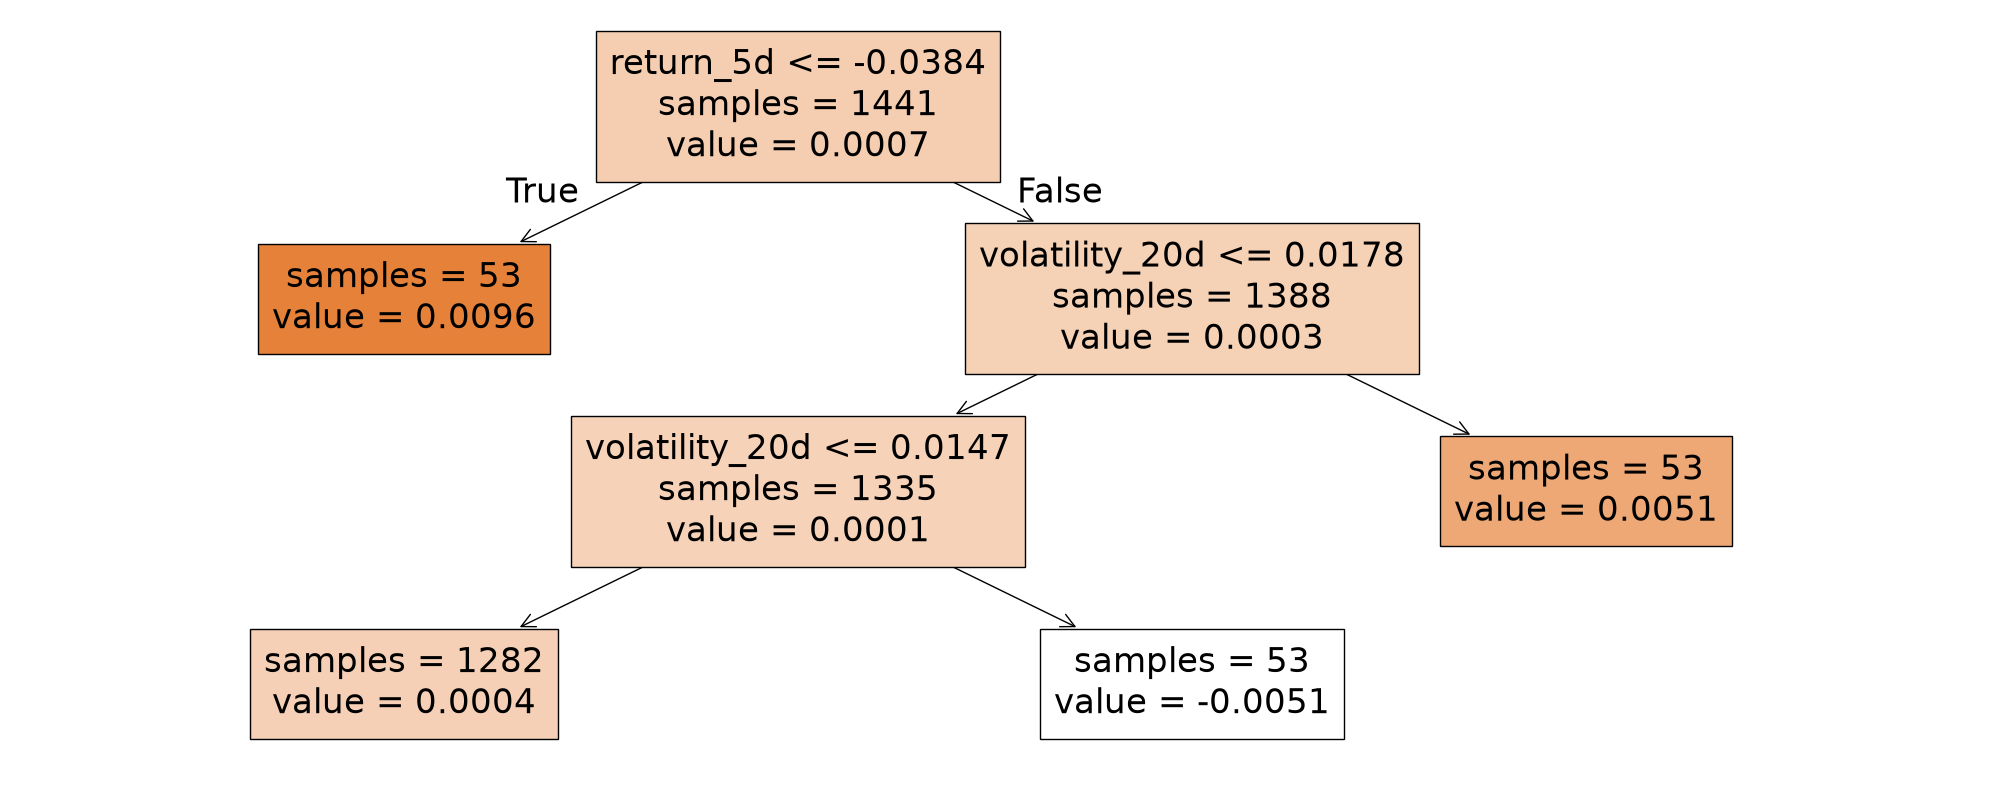

In [ ]:
from sklearn.tree import plot_tree

fig, ax = plt.subplots(figsize=(20, 8))

plot_tree(
    forest_selected.estimators_[0],
    feature_names=X_train.columns.tolist(),
    filled=True,
    impurity=False,
    precision=4,
    ax=ax,
)

plt.tight_layout()
plt.show()

In [ ]:
mean_train_mse = ((y_train - train_mean) ** 2).mean()
mean_validation_mse = ((y_validation - train_mean) ** 2).mean()

forest_comparison = pd.DataFrame(
    {
        "historical_mean_mse": [
            mean_train_mse,
            mean_validation_mse,
        ],
        "random_forest_mse": [
            forest_train_mse,
            forest_validation_mse,
        ],
    },
    index=["Training", "Validation"],
)

forest_comparison["relative_mse_reduction"] = (
    1
    - forest_comparison["random_forest_mse"]
    / forest_comparison["historical_mean_mse"]
)

display(forest_comparison)

,historical_mean_mse,random_forest_mse,relative_mse_reduction
Training,0.000088,0.000086,0.024551
Validation,0.000201,0.000202,-0.003603


In [ ]:
#%pip install xgboost
import xgboost as xgb

print("XGBoost version:", xgb.__version__)

XGBoost version: 3.4.1


In [ ]:
xgb_model = xgb.XGBRegressor(
    objective="reg:squarederror",
    n_estimators=200,
    learning_rate=0.03,
    max_depth=2,
    min_child_weight=50,
    reg_lambda=1.0,
    random_state=42,
)

xgb_model.fit(X_train, y_train)

validation_predictions["xgboost"] = xgb_model.predict(X_validation)

xgb_mse = (
    validation_predictions["actual"]
    - validation_predictions["xgboost"]
).pow(2).mean()

print("XGBoost validation MSE:", xgb_mse)

XGBoost validation MSE: 0.00020109436727100373


## Validation set

**Observations**

Model rankings vary across validation years.
The linear models outperform both baselines in 2019–2021,
but underperform both baselines in 2022.

Much of their aggregate MSE improvement comes from 2020.

**Interpretation**

The validation advantage is not consistent across years.
The aggregate result alone does not establish stable
predictive performance.

In [38]:
prediction_columns = [
    "zero",
    "historical_mean",
    "ols",
    "ridge",
    "lasso",
    "random_forest",
    "xgboost",
]

squared_errors = validation_predictions[prediction_columns].sub(
    validation_predictions["actual"],
    axis=0,
).pow(2)

yearly_mse = squared_errors.groupby(squared_errors.index.year).mean()
yearly_mse.index.name = "prediction_year"

with pd.option_context("display.precision", 12):
    display(yearly_mse)

,zero,historical_mean,ols,ridge,lasso,random_forest,xgboost
prediction_year,,,,,,,
2019,0.000063440027,0.000062560948,0.000062096264,0.000062098618,0.000062109167,0.000062194014,0.000062021864
2020,0.000442054647,0.000441513752,0.000431800868,0.000431815819,0.000431634702,0.000442506774,0.000436227150
2021,0.000067152597,0.000066302754,0.000065528668,0.000065509542,0.000065518440,0.000066218905,0.000067093932
2022,0.000233556609,0.000234489529,0.000236887004,0.000236596425,0.000236717175,0.000236861721,0.000238397513


In [39]:
development = pd.concat([train, validation]).sort_index()

X_development = development[feature_columns]
y_development = development[target_column]

final_model = make_pipeline(
    StandardScaler(),
    Lasso(alpha=0.00001),
)

final_model.fit(X_development, y_development)

final_train_mean = y_development.mean()

print("Development rows:", len(development))
print("Latest training target date:", development["target_date"].max())
print("First test prediction date:", test.index.min())

Development rows: 3250
Latest training target date: 2022-12-30 00:00:00
First test prediction date: 2023-01-03 00:00:00


**Final test result**

The selected Lasso model achieves a test MSE of 0.000092472119,
approximately 1.11% lower than the historical-mean baseline
and 1.78% lower than the zero-return baseline.

**Limitations**

This result does not establish statistical significance,
future persistence, or trading profitability.

In [40]:
X_test = test[feature_columns]

test_predictions = pd.DataFrame(index=test.index)
test_predictions["actual"] = test[target_column]
test_predictions["zero"] = 0.0
test_predictions["historical_mean"] = final_train_mean
test_predictions["lasso"] = final_model.predict(X_test)

test_mse = (
    test_predictions[["zero", "historical_mean", "lasso"]]
    .sub(test_predictions["actual"], axis=0)
    .pow(2)
    .mean()
)

test_results = test_mse.rename("test_mse").to_frame()

with pd.option_context("display.precision", 12):
    display(test_results)

,test_mse
zero,0.000094150676
historical_mean,0.000093510796
lasso,0.000092472119


**Yearly test observations**

Lasso underperforms both baselines in 2023 and 2024,
but outperforms them in 2025.

Its aggregate test MSE improvement is driven by 2025.

**Interpretation**

The aggregate improvement does not establish a consistent
advantage across years.

In [41]:
Path("results").mkdir(exist_ok=True)

test_predictions.to_csv("results/lasso_test_predictions.csv")
test_results.to_csv("results/lasso_test_mse.csv")

test_squared_errors = (
    test_predictions[["zero", "historical_mean", "lasso"]]
    .sub(test_predictions["actual"], axis=0)
    .pow(2)
)

yearly_test_mse = test_squared_errors.groupby(
    test_squared_errors.index.year
).mean()

yearly_test_mse.index.name = "prediction_year"

yearly_test_mse["lasso_reduction_vs_mean"] = (
    1 - yearly_test_mse["lasso"] / yearly_test_mse["historical_mean"]
)

yearly_test_mse.to_csv("results/lasso_yearly_test_mse.csv")

with pd.option_context("display.precision", 12):
    display(yearly_test_mse)

,zero,historical_mean,lasso,lasso_reduction_vs_mean
prediction_year,,,,
2023,0.000068558189,0.000067831380,0.000069460433,-0.024016204283
2024,0.000063175466,0.000062482637,0.000063850620,-0.021893805546
2025,0.000151194347,0.000150695333,0.000144542560,0.040829220717


## Research Summary

**Research question**

Can SPY's past returns and volatility help predict its
next-trading-day return beyond simple baselines?

**Method**

Six features were constructed using information available
after each trading day's close: current daily return,
two lagged daily returns, 5-day and 20-day cumulative
returns, and 20-day rolling volatility.

Models were initially fitted on 2010–2018 data and compared
on 2019–2022 validation data. Lasso with alpha=0.00001 was
selected, then refitted on the combined development data
before evaluation on the held-out 2023–2025 test period.

**Results**

Lasso reduced aggregate test MSE by approximately 1.11%
relative to the historical-mean baseline and 1.78%
relative to the zero-return baseline.

However, it underperformed both baselines in 2023 and 2024.
The aggregate improvement was driven by 2025.

**Conclusion**

The selected model improved aggregate test MSE, but did
not demonstrate a consistent advantage across years.

**Limitations**

Statistical significance and trading profitability have
not been established. Predictions use information available
after the close, so execution at that same closing price
cannot be assumed.

The data are a downloaded historical snapshot of
vendor-adjusted prices, not a verified point-in-time dataset.

**Reproducibility check**

The notebook ran successfully from a restarted kernel using
the saved CSV snapshot. No errors occurred, and yearly test
results matched the previously recorded values at the
displayed precision.

In [42]:
import sys
from pathlib import Path

import pandas as pd
import numpy as np
import sklearn
import xgboost as xgb

print("Python:", sys.version)
print("pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("scikit-learn:", sklearn.__version__)
print("XGBoost:", xgb.__version__)
print("Working directory:", Path.cwd())

Python: 3.14.7 (tags/v3.14.7:823f032, Aug  5 2026, 10:51:32) [MSC v.1944 64 bit (AMD64)]
pandas: 3.1.0
NumPy: 2.5.4
scikit-learn: 1.9.1
XGBoost: 3.4.1
Working directory: c:\Users\yeung\OneDrive\Documents\ChatGPT\Thomas Math\Quant_Project_1_corrected


In [43]:
from importlib.metadata import version

for package in ["matplotlib", "yfinance", "ipykernel"]:
    print(f"{package}=={version(package)}")

matplotlib==3.11.2
yfinance==1.7.0
ipykernel==7.4.0
